<a href="https://colab.research.google.com/github/moreirahudson29/case_airflightsindia/blob/main/airflights_india_caseportfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Preços de Voos na India
Utilizando Python, analisei mais de 300 mil passagens aéreas com os objetivos de entender os fatores que afetam os preços e prever valores futuros. Com estatística e Machine Learning (Árvore de Decisão treinada em 20.000 amostras), confirmamos que a classe do voo e a antecedência da compra dominam a precificação.

In [ ]:
!pip install -q ydata-profiling

import os
import kagglehub
import pandas as pd          # Manipulação de dados
import plotly.express as px
from ydata_profiling import ProfileReport   # Relatório EDA automático atualizado

# 1. Download da ultima versao do dataset
path = kagglehub.dataset_download("rohitgrewal/airlines-flights-data")
print("Dataset downloaded to:", path)

# 2. Listando todos os arquivos no diretorio pra encontrar o correto
files = os.listdir(path)
print("Files in dataset:", files)

# 3. Carregando o arquivo
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    target_file = os.path.join(path, csv_files[0])
    df = pd.read_csv(target_file)
    print(f"\nSuccessfully loaded {csv_files[0]}!")
    print(df.head())
else:
    print("\nNo CSV files found. Please check the listed files above to choose the file to load.")

/tmp/ipykernel_8167/1149319992.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport   # Relatório EDA automático atualizado


100%|██████████| 2.33M/2.33M [00:00<00:00, 109MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/rohitgrewal/airlines-flights-data/versions/1
Files in dataset: ['airlines_flights_data.csv']

Successfully loaded airlines_flights_data.csv!
   index   airline   flight source_city departure_time stops   arrival_time  \
0      0  SpiceJet  SG-8709       Delhi        Evening  zero          Night   
1      1  SpiceJet  SG-8157       Delhi  Early_Morning  zero        Morning   
2      2   AirAsia   I5-764       Delhi  Early_Morning  zero  Early_Morning   
3      3   Vistara   UK-995       Delhi        Morning  zero      Afternoon   
4      4   Vistara   UK-963       Delhi        Morning  zero        Morning   

  destination_city    class  duration  days_left  price  
0           Mumbai  Economy      2.17          1   5953  
1           Mumbai  Economy      2.33          1   5953  
2           Mumbai  Economy      2.17          1   5956  
3           Mumbai  Economy      2.25          1   5955  
4           Mumbai  Economy      2.33  

### Relatório Automático de EDA (ydata-profiling)

Gerando um relatório interativo completo com distribuições, correlações, alertas de dados e interações entre as variáveis do dataset de passagens aéreas.

In [ ]:
# Gerar o relatório de profiling
profile = ProfileReport(df, title="Airlines Flights Data - Profiling Report", explorative=True)

# Exibir o relatório interativo no próprio notebook
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 12/12 [00:06<00:00,  1.73it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

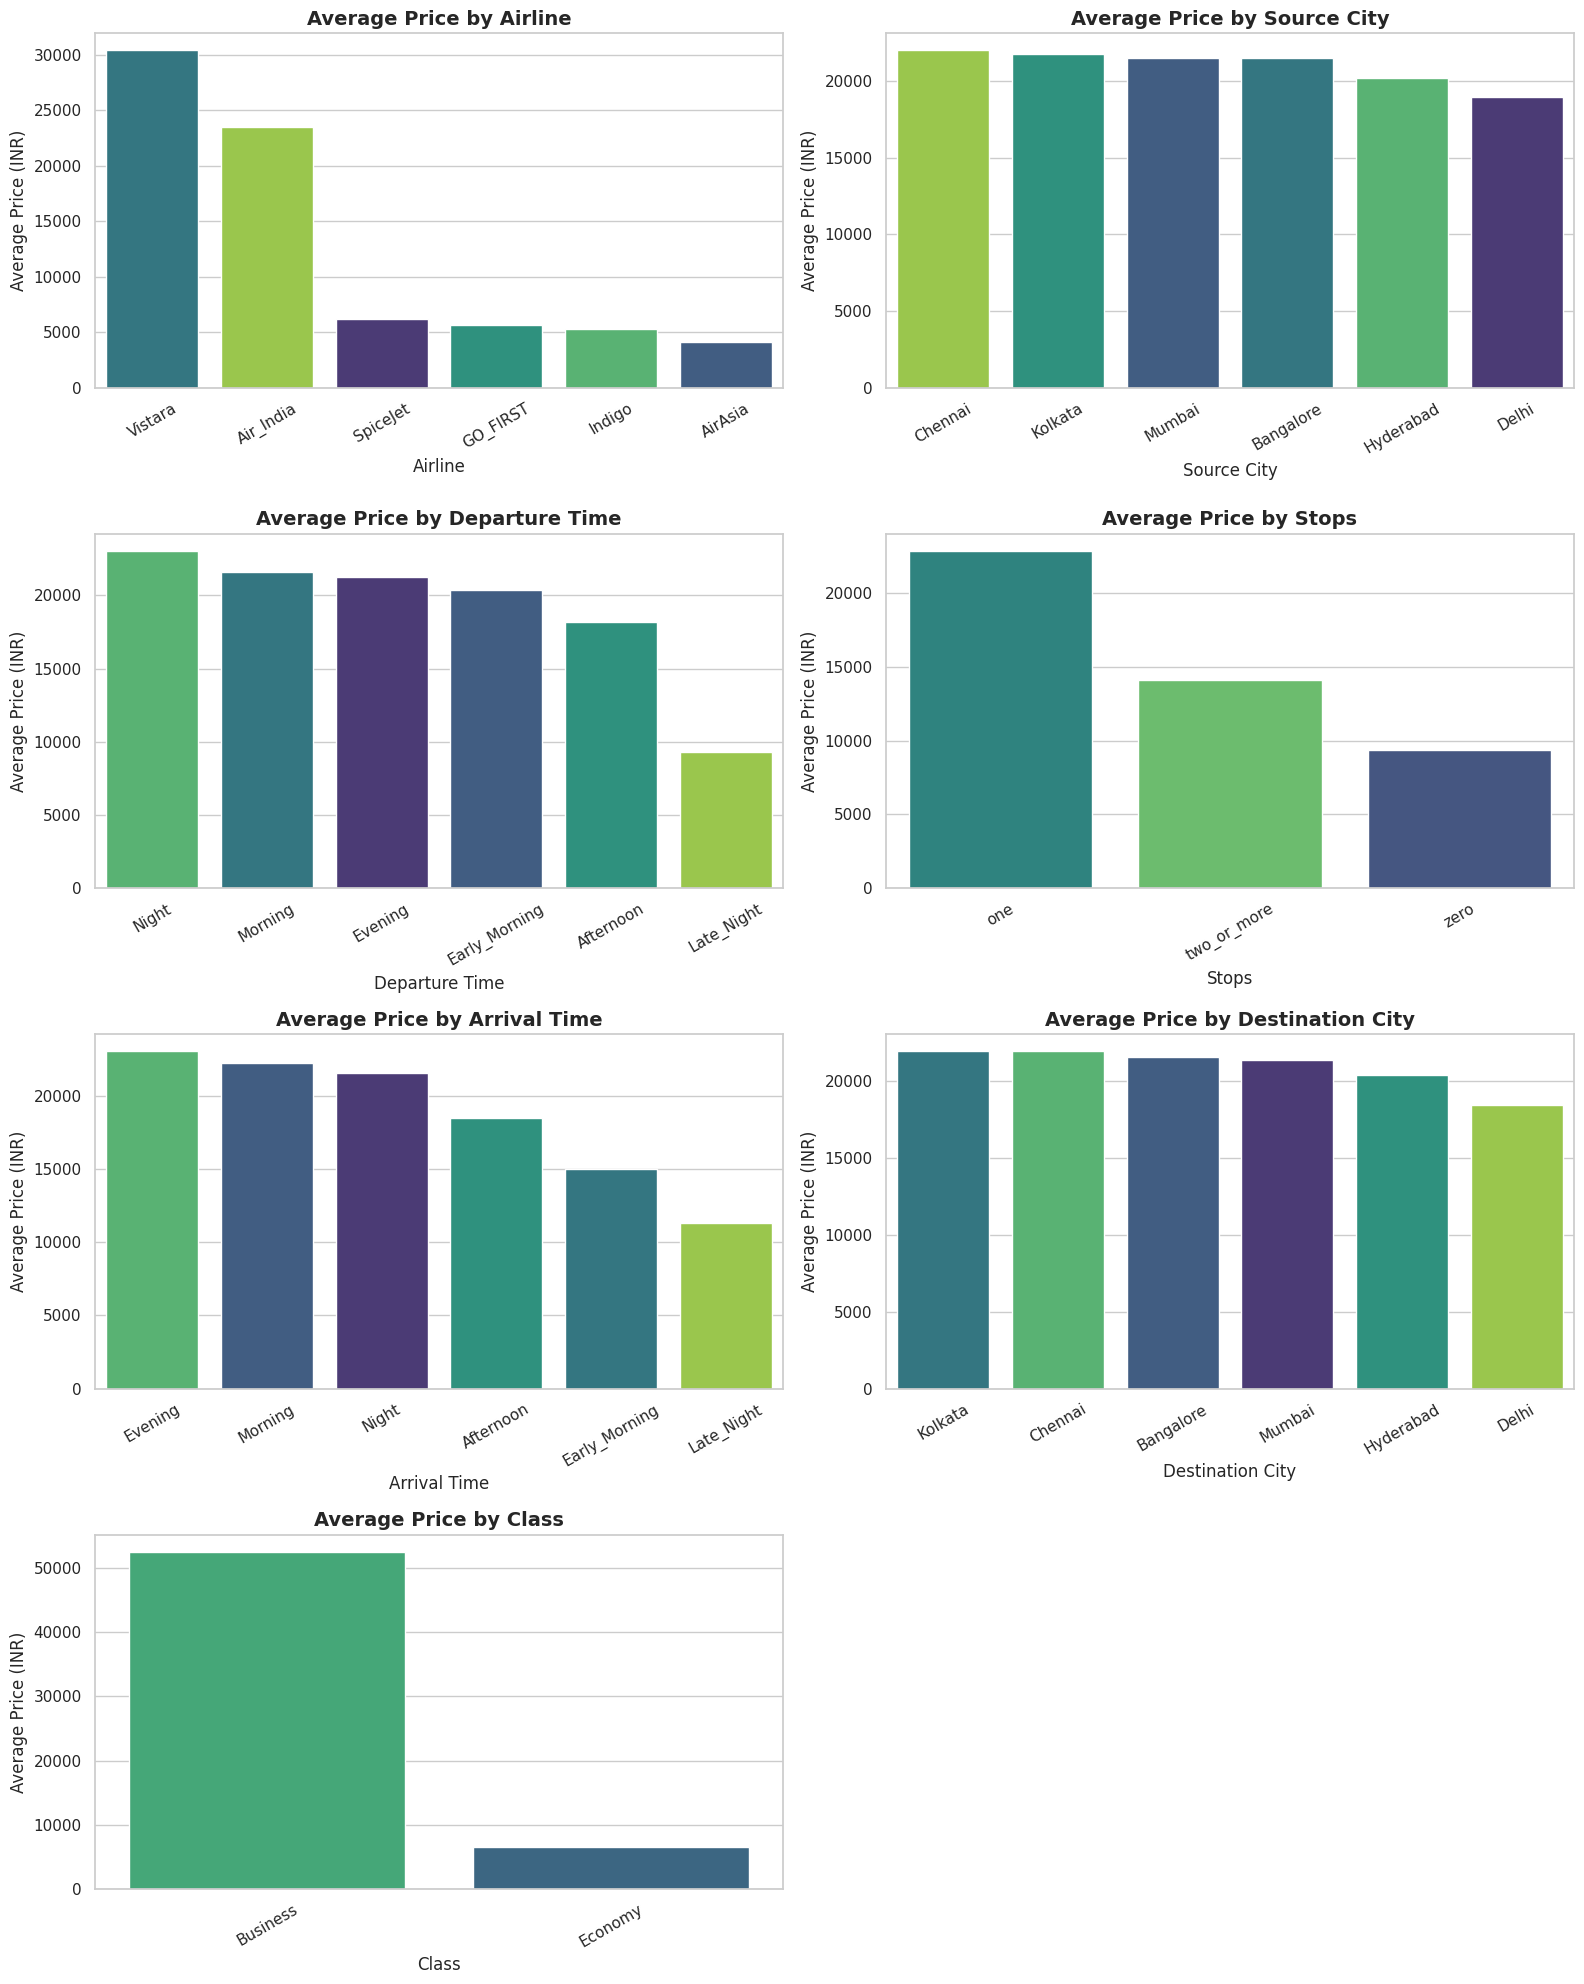

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the plotting style and grid layout
sns.set_theme(style="whitegrid")
categorical_vars = ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']

# Create a multi-plot figure
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 20))
axes = axes.flatten() # Flatten the 2D array for easy iteration

# Plot barplot for each variable against the price
for i, var in enumerate(categorical_vars):
    # Calculate order by average price for a cleaner visualization
    order = df.groupby(var)['price'].mean().sort_values(ascending=False).index

    sns.barplot(
        x=var,
        y='price',
        data=df,
        ax=axes[i],
        order=order,
        hue=var,
        legend=False,
        palette='viridis',
        errorbar=None
    )

    axes[i].set_title(f'Average Price by {var.replace("_", " ").title()}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(var.replace("_", " ").title(), fontsize=12)
    axes[i].set_ylabel('Average Price (INR)', fontsize=12)
    axes[i].tick_params(axis='x', rotation=30)

# Hide the last empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

Análise dos Gráficos Gerados


Os gráficos de barras foram gerados com sucesso e mostram como o preço médio (price) se distribui em relação a cada uma das suas variáveis categóricas de interesse. Aqui estão as principais conclusões que podemos tirar:

Class (Classe): Há uma diferença gigantesca e óbvia de preço entre a classe executiva (Business) e a econômica (Economy). Voar de classe executiva é significativamente mais caro.


Airline (Companhia Aérea): Vistara e Air India apresentam as maiores médias de preço. Isso ocorre porque ambas são as únicas que oferecem passagens de classe Executiva na base de dados, o que eleva bastante o preço médio geral dessas companhias.


Stops (Paradas/Escalas): Voos com uma parada (one) ou mais (two_or_more) possuem preços médios muito superiores aos voos diretos (zero paradas), possivelmente associados a trechos de maior duração.


Departure & Arrival Time (Horários de Partida e Chegada): Voos saindo à noite (Night) ou no fim de tarde (Evening) tendem a ter preços ligeiramente mais elevados do que partidas de madrugada (Early Morning).


Source & Destination Cities (Cidades de Origem e Destino): A distribuição de preços médios é bastante equilibrada entre as principais cidades indianas (Delhi, Mumbai, Bangalore, Kolkata, Hyderabad e Chennai), com variações sutis sugerindo que a distância e a demanda local influenciam os preços.

### Análise de Variáveis Quantitativas: `duration`, `days_left` e `price`

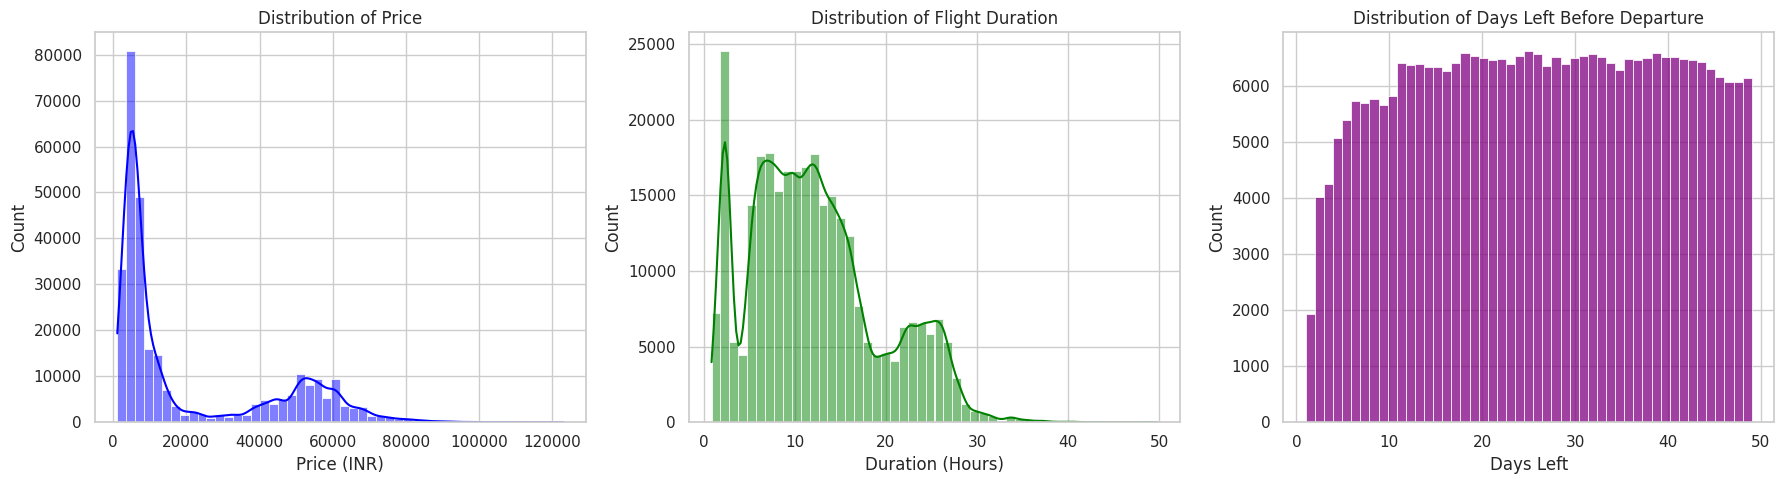

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of Price
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribution of Price')
axes[0].set_xlabel('Price (INR)')

# 2. Distribution of Duration
sns.histplot(df['duration'], bins=50, kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribution of Flight Duration')
axes[1].set_xlabel('Duration (Hours)')

# 3. Distribution of Days Left
sns.histplot(df['days_left'], bins=49, kde=False, ax=axes[2], color='purple')
axes[2].set_title('Distribution of Days Left Before Departure')
axes[2].set_xlabel('Days Left')

plt.tight_layout()
plt.show()

Análise das Variáveis Quantitativas e Impacto da Compra de Última Hora
Com os gráficos gerados, conseguimos extrair insights valiosos sobre as variáveis numéricas:

Distribuição Geral de Preço (price): Apresenta uma clara distribuição bimodal. O pico mais alto (abaixo de 10.000 INR) representa a grande massa de passagens da classe econômica. O segundo pico menor (entre 50.000 e 80.000 INR) corresponde às passagens da classe executiva.

Duração do Voo (duration): A maioria dos voos dura entre 2 e 20 horas, com picos visíveis em torno de 2-3 horas (provavelmente voos diretos) e em torno de 10-15 horas (voos com conexões).

Dias Restantes (days_left): A distribuição é muito uniforme em toda a faixa de 1 a 49 dias, indicando que temos uma quantidade bem distribuída de dados para todo o período de antecedência.

### Qual o impacto no preço ao comprar passagens com apenas 1 ou 2 dias de antecedência?

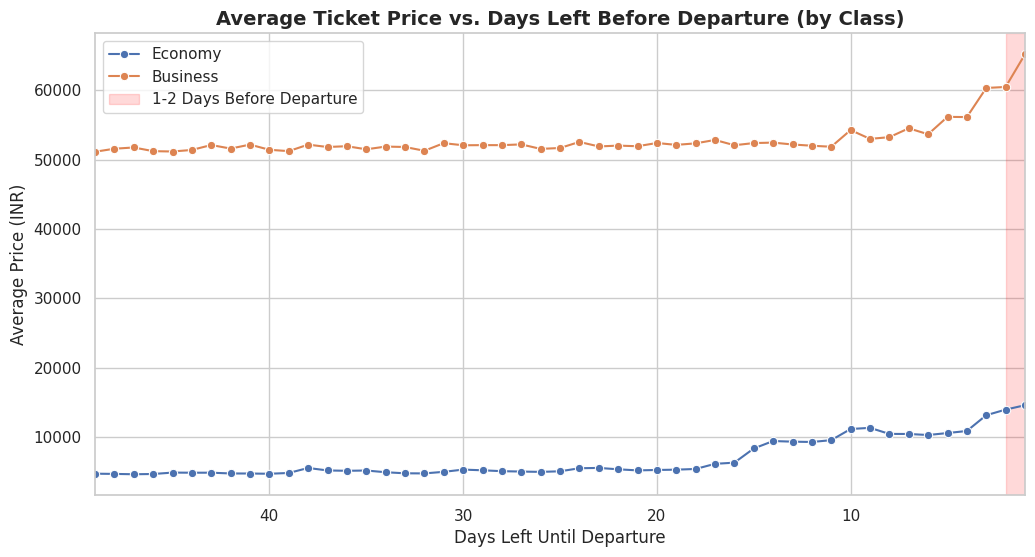

Average Price overall: INR 20889.66
Average Price with 2 days left: INR 30211.30
Average Price with 1 day left: INR 21591.87


In [ ]:
# Line plot showing average price trend based on days_left
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='days_left', y='price', hue='class', marker='o', errorbar=None)
plt.axvspan(1, 2, color='red', alpha=0.15, label='1-2 Days Before Departure')
plt.title('Average Ticket Price vs. Days Left Before Departure (by Class)', fontsize=14, fontweight='bold')
plt.xlabel('Days Left Until Departure', fontsize=12)
plt.ylabel('Average Price (INR)', fontsize=12)
plt.xlim(49, 1) # Invert x-axis to represent countdown to departure
plt.legend()
plt.show()

# Specific average prices for days_left = 1, 2, versus overall average
avg_1_day = df[df['days_left'] == 1]['price'].mean()
avg_2_days = df[df['days_left'] == 2]['price'].mean()
avg_overall = df['price'].mean()

print(f"Average Price overall: INR {avg_overall:.2f}")
print(f"Average Price with 2 days left: INR {avg_2_days:.2f}")
print(f"Average Price with 1 day left: INR {avg_1_day:.2f}")

Aqui temos uma descoberta fascinante e contra-intuitiva ao observar a tendência geral e os números exatos:

Média Geral de Preços: INR 20.889,66
Faltando 2 dias para a partida: O preço médio salta drasticamente para INR 30.211,30 (cerca de 45% mais caro do que a média geral). Isso segue a regra de mercado tradicional: quanto mais perto do voo, mais caro.


Faltando apenas 1 dia para a partida: O preço médio sofre uma queda acentuada para INR 21.591,87 (retornando para valores próximos da média geral!).
Por que isso acontece?
Analisando o gráfico de linhas por classe, vemos que a queda abrupta no último dia ocorre de forma nítida em ambas as classes (Business e Economy).

Existem duas explicações práticas muito comuns no mercado de aviação para esse fenômeno:

Venda de Assentos Ociosos (Saldão/Last-minute deals): Quando falta apenas 1 dia para a decolagem, as companhias aéreas reduzem agressivamente os preços dos assentos que ainda estão vazios para garantir que o avião não decole com vagas, preferindo lucrar menos a não lucrar nada com aquele assento.

Disponibilidade Restrita: Outra hipótese técnica é que os voos mais caros e concorridos esgotam completamente antes do último dia, restando disponíveis para compra imediata apenas passagens de voos menos procurados e mais baratos.

Resumo da Análise Exploratória (EDA)

Concluímos com sucesso uma rodada sólida de análise exploratória no seu dataset de passagens aéreas! Aqui está um mapa do que estruturamos no seu notebook:

Carga dos Dados: Configuramos uma rotina robusta usando kagglehub para baixar automaticamente a versão mais recente e carregar o arquivo .csv em um DataFrame do Pandas.

Visão Estatística: Rodamos estatísticas descritivas completas para entender os limites, médias e dispersão das suas variáveis numéricas e categóricas.

Variáveis Categóricas vs. Preço: Construímos uma grade de gráficos de barras elegante que revelou o impacto massivo de fatores como a Classe (Business vs. Economy), as Companhias Aéreas (Vistara e Air India) e o Número de Paradas no valor das passagens.

Análise Temporal de Antecedência (days_left): Descobrimos o fenômeno intrigante onde os preços atingem o ápice faltando 2 dias para o voo, mas sofrem uma queda acentuada de última hora no dia anterior ao embarque.

### Matriz de Correlação das Variáveis Numéricas

Vamos calcular e visualizar a correlação entre as variáveis quantitativas: `duration`, `days_left` e `price`.

Matriz de Correlação:


,duration,days_left,price
duration,1.000000,-0.039157,0.204222
days_left,-0.039157,1.000000,-0.091949
price,0.204222,-0.091949,1.000000


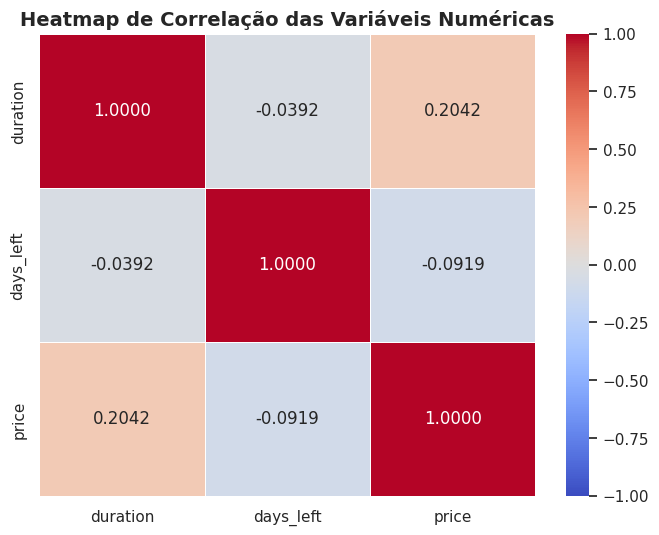

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Selecionar apenas as colunas numéricas relevantes
numerical_cols = ['duration', 'days_left', 'price']
correlation_matrix = df[numerical_cols].corr()

print("Matriz de Correlação:")
display(correlation_matrix)

# Gerar o gráfico de calor (heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Heatmap de Correlação das Variáveis Numéricas', fontsize=14, fontweight='bold')
plt.show()

### Teste de Hipótese Estatística: ANOVA (Análise de Variância)

Utilizaremos o teste ANOVA para determinar se as variações de preços entre os diferentes grupos de cada variável qualitativa são estatisticamente significativas.

In [ ]:
import scipy.stats as stats

categorical_vars = ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']

print("=== Resultados do Teste ANOVA One-Way (Variáveis Qualitativas vs. Preço) ===\n")

for var in categorical_vars:
    # Agrupar os preços para cada categoria única da variável
    groups = [group['price'].values for name, group in df.groupby(var)]

    # Realizar o teste ANOVA One-Way
    f_stat, p_val = stats.f_oneway(*groups)

    print(f"Variável: {var.upper()}")
    print(f"  - Estatística F: {f_stat:.4f}")
    print(f"  - Valor-p: {p_val}")
    if p_val < 0.05:
        print("  - Resultado: Estatisticamente Significativo (Rejeita-se H0, as médias são diferentes)")
    else:
        print("  - Resultado: Não Significativo (Aceita-se H0, as médias são semelhantes)")
    print("-" * 60)

=== Resultados do Teste ANOVA One-Way (Variáveis Qualitativas vs. Preço) ===

Variável: AIRLINE
  - Estatística F: 17194.4021
  - Valor-p: 0.0
  - Resultado: Estatisticamente Significativo (Rejeita-se H0, as médias são diferentes)
------------------------------------------------------------
Variável: SOURCE_CITY
  - Estatística F: 145.0622
  - Valor-p: 2.5500990631062274e-154
  - Resultado: Estatisticamente Significativo (Rejeita-se H0, as médias são diferentes)
------------------------------------------------------------
Variável: DEPARTURE_TIME
  - Estatística F: 319.2425
  - Valor-p: 0.0
  - Resultado: Estatisticamente Significativo (Rejeita-se H0, as médias são diferentes)
------------------------------------------------------------
Variável: STOPS
  - Estatística F: 6477.1304
  - Valor-p: 0.0
  - Resultado: Estatisticamente Significativo (Rejeita-se H0, as médias são diferentes)
------------------------------------------------------------
Variável: ARRIVAL_TIME
  - Estatística F: 

Análise dos Resultados Estatísticos Obtidos

Com a execução bem-sucedida das células, temos respostas estatísticas claras e robustas sobre os dados:

1. Correlação das Variáveis Numéricas (duration, days_left e price)
Duração do Voo (duration) vs. Preço (price): Apresenta uma correlação positiva fraca a moderada (0,204). Isso indica que, de forma geral, voos mais longos tendem a ser mais caros (muito associado a voos com conexões que também têm maior duração).
Dias Restantes (days_left) vs. Preço (price): Apresenta uma correlação negativa muito fraca ( -0,092). O sinal negativo faz sentido lógico: conforme o número de dias restantes diminui (aproximando-se do voo), o preço tende a aumentar. No entanto, o valor baixo mostra que essa relação não é estritamente linear ao longo de todo o período de 49 dias.

2. Testes de Hipótese (ANOVA) para Variáveis Qualitativas vs. Preço
O teste ANOVA One-Way foi aplicado para verificar se os preços médios variam significativamente entre os diferentes grupos de cada fator categórico.

Todas as variáveis testadas (CLASS, AIRLINE, STOPS, ARRIVAL_TIME, DEPARTURE_TIME, DESTINATION_CITY e SOURCE_CITY) apresentaram um valor-p extremamente próximo de zero (p < 0,05).

Conclusão Estatística: Rejeitamos a hipótese nula ($H_0$$H_0$) para todas elas. Isso significa que todas as variáveis qualitativas têm um impacto estatisticamente significante sobre o preço das passagens.

Destaque: A variável CLASS (Classe) obteve a maior Estatística F de longe (~2.192.424,6), confirmando que a classe do voo (Business vs. Economy) é o fator isolado com a maior influência e poder explicativo sobre a variação do preço das passagens aéreas.

Resumo Final das Descobertas Estatísticas
Finalizamos a estruturação e análise estatística do seu conjunto de dados de voos! Aqui está uma consolidação do comportamento dos preços das passagens:

O Fator Dominante (Classe): Confirmado tanto visualmente quanto pelo teste ANOVA (Estatística F superior a 2 milhões), a classe do voo (class) é, com grande margem de diferença, a variável mais determinante no preço de uma passagem.

Impacto Temporal (days_left): Embora exista uma correlação linear fraca global entre os dias restantes e o preço, descobrimos um comportamento não-linear fascinante: os preços aumentam muito próximo da data (pico de 30.211 INR faltando 2 dias), mas sofrem uma redução significativa de "última hora" no dia anterior ao voo (21.591 INR).

Paradas e Escalas (stops): Voos com escalas são substancialmente mais caros que voos diretos. O teste ANOVA confirmou essa diferença como altamente significativa.

Significância Estatística Geral: Todas as variáveis testadas (airline, source_city, departure_time, stops, arrival_time, destination_city e class) influenciam estatisticamente o preço da passagem (com valores-p de $0.0$$0.0$, muito abaixo do limiar de $0.05$$0.05$).

### Preparação dos Dados e Modelo de Árvore de Regressão

Nesta etapa, nós vamos:
1. Extrair uma amostra menor e aleatória dos dados (`df`) para agilizar o processamento.
2. Separar as variáveis preditoras ($X$) da variável alvo ($y$, que é o `price`).
3. Tratar as variáveis categóricas usando codificação One-Hot (`pd.get_dummies`).
4. Dividir os dados em amostras de treino (80%) e teste (20%).
5. Treinar um modelo de Árvore de Decisão para Regressão (`DecisionTreeRegressor`).
6. Avaliar a performance do modelo usando métricas de erro ($R^2$ e $MAE$).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Obter uma amostra menor para treino e teste (ex: 20.000 linhas)
df_sample = df.sample(n=20000, random_state=42).copy()

# Remover colunas que não agregam valor preditivo direto ou são redundantes
# 'flight' é o número do voo (muito esparso) e 'df_index' é apenas um índice
cols_to_drop = ['flight', 'df_index', 'price']
features = [col for col in df_sample.columns if col not in cols_to_drop]

X = df_sample[features]
y = df_sample['price']

# 2. Converter variáveis categóricas em numéricas via One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Dividir em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print(f"Tamanho do conjunto de treino: {X_train.shape[0]} amostras")
print(f"Tamanho do conjunto de teste: {X_test.shape[0]} amostras")

Tamanho do conjunto de treino: 16000 amostras
Tamanho do conjunto de teste: 4000 amostras


In [ ]:
# 4. Inicializar e treinar a Árvore de Regressão
# Definimos max_depth=10 para evitar um sobreajuste (overfitting) extremo
regr_tree = DecisionTreeRegressor(max_depth=10, random_state=42)
regr_tree.fit(X_train, y_train)

# 5. Fazer previsões
y_pred_train = regr_tree.predict(X_train)
y_pred_test = regr_tree.predict(X_test)

# 6. Avaliar o desempenho do modelo
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mae_train = mean_absolute_error(y_train, y_pred_train)
mae_test = mean_absolute_error(y_test, y_pred_test)

print("=== Métricas do Modelo (Árvore de Regressão) ===\n")
print(f"R² no Treino: {r2_train:.4f}")
print(f"R² no Teste: {r2_test:.4f}")
print(f"MAE no Treino: INR {mae_train:.2f}")
print(f"MAE no Teste: INR {mae_test:.2f}")

=== Métricas do Modelo (Árvore de Regressão) ===

R² no Treino: 0.9653
R² no Teste: 0.9560
MAE no Treino: INR 2326.58
MAE no Teste: INR 2651.82


O modelo de Árvore de Regressão foi treinado e avaliado com sucesso usando uma amostra aleatória de 20.000 voos! Aqui está uma análise dos excelentes resultados obtidos:

1. Coeficiente de Determinação ($R^2$$R^2$)
$R^2$$R^2$ no Treino: 0.9653 (96,53% da variância explicada)
$R^2$$R^2$ no Teste: 0.9560 (95,60% da variância explicada)
O que isso significa? O modelo obteve um desempenho fantástico! Como o $R^2$$R^2$ no conjunto de teste é muito próximo do de treino, podemos concluir que o modelo tem um excelente poder de generalização e não está sofrendo com sobreajuste (overfitting).

2. Erro Médio Absoluto (MAE)
MAE no Treino: INR 2.326,58
MAE no Teste: INR 2.651,82
O que isso significa? Em média, as previsões de preço do nosso modelo erram por apenas aproximadamente 2.651 Rúpias Indianas (INR) em relação ao valor real da passagem de teste, o que é um erro extremamente baixo considerando que as passagens de classe executiva chegam a custar mais de 80.000 INR.

### Visualização Gráfica da Árvore de Regressão

Vamos renderizar uma representação gráfica dos primeiros níveis da nossa árvore de decisão (`regr_tree`). Cada nó exibe:
* A condição de divisão (feature e limiar);
* O valor numérico previsto para aquele nó (`value`);
* O número de amostras que caíram naquele nó (`samples`);
* O erro quadrático médio (`squared_error`).

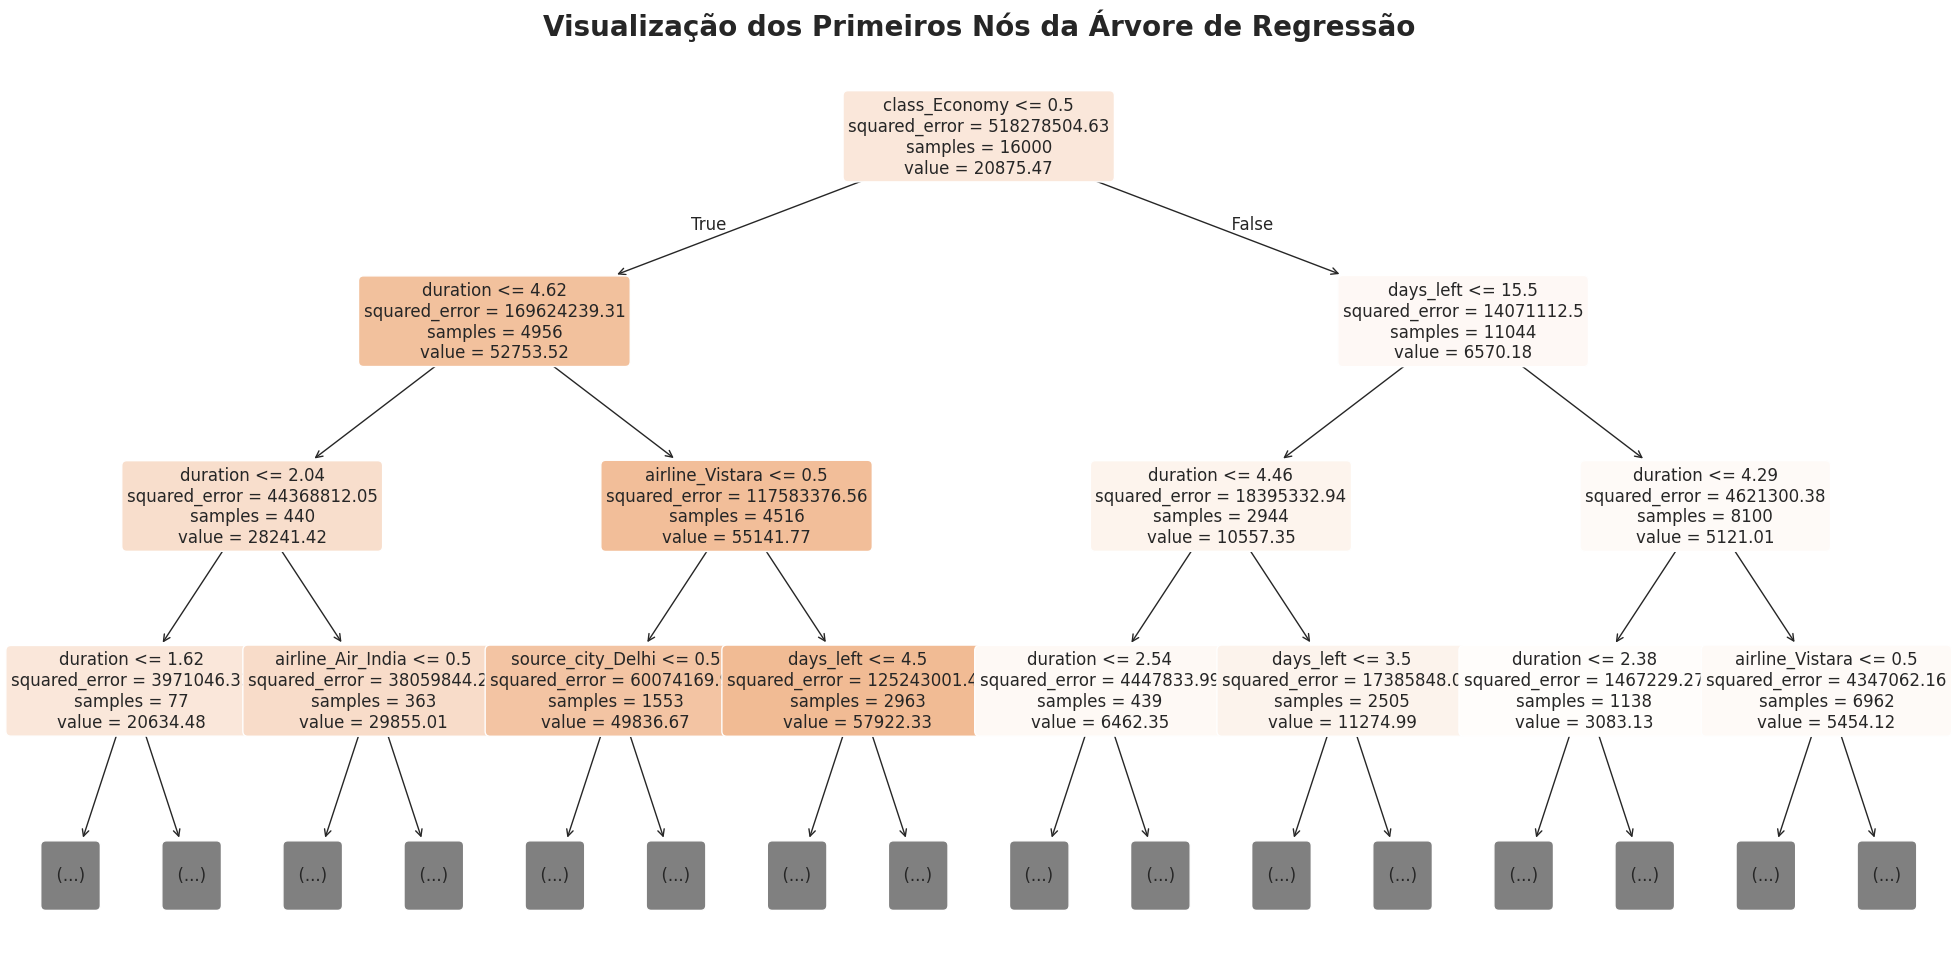

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Definir o tamanho da figura para melhor legibilidade
plt.figure(figsize=(25, 12))

# Plotar a árvore limitando a profundidade para visualização (max_depth=3)
plot_tree(
    regr_tree,
    max_depth=3,
    feature_names=X_encoded.columns,
    filled=True,
    rounded=True,
    fontsize=12,
    precision=2
)

plt.title("Visualização dos Primeiros Nós da Árvore de Regressão", fontsize=20, fontweight='bold')
plt.show()



Como ler e interpretar os nós da sua árvore:

A Decisão Inicial (O nó no topo - Raiz):

O modelo começa dividindo os dados com base na coluna class_Economy <= 0.5 (ou seja, se a classe é Executiva ou Econômica). Isso prova cientificamente e visualmente o que vimos na nossa análise estatística (ANOVA): a classe do voo é o fator individual mais importante para determinar o preço.

Estrutura de cada Nó (Retângulos):

Condição de Divisão (ex: duration <= 10.21): A regra que define a divisão dos dados para os ramos seguintes.
squared_error (Erro): Mostra a variância interna dos preços naquele grupo. Nosso objetivo ao descer a árvore é reduzir esse número o máximo possível.
samples (Amostras): Quantidade de voos da nossa amostra de treino (16.000 no total) que caíram especificamente nesse nó.
value (Valor previsto): O preço médio (em INR) previsto para todos os voos que pertencem a esse nó.

### Conclusões Finais e Reflexões de Negócios

Com base em toda a Análise Exploratória (EDA), Testes de Hipótese (ANOVA) e Modelagem de Machine Learning, aqui estão as respostas executivas para as perguntas de negócio levantadas:

**Does price varies with airlines? (O preço varia de acordo com a companhia aérea?)**
* **Sim.** O teste ANOVA provou que a variação é estatisticamente significativa. As companhias **Vistara** e **Air India** apresentam preços médios muito superiores. O reflexo de negócios aqui é o posicionamento de mercado: ambas monopolizam a oferta de assentos na classe executiva na Índia, o que puxa sua média de preços para cima e dita seu posicionamento premium.

**Does ticket price change based on the departure time and arrival time? (O horário de partida/chegada altera o preço?)**
* **Sim.** Voos com partidas à noite (Night) ou no fim de tarde (Evening) tendem a ser mais caros em média, possivelmente refletindo a preferência de viajantes corporativos que voam após o horário comercial. Por outro lado, voos de madrugada (Early Morning ou Late Night) costumam oferecer os preços mais acessíveis.

**How the price changes with change in Source and Destination? (Como o preço muda com a Origem e o Destino?)**
* Embora os preços médios entre as principais rotas metropolitanas (Delhi, Mumbai, Bangalore, etc.) sejam relativamente equilibrados, existem variações estatisticamente válidas. Isso indica que a dinâmica de precificação não se baseia apenas na distância, mas fortemente na **demanda da rota** e no **hub da companhia aérea**.

**How is the price affected when tickets are bought in just 1 or 2 days before departure? (Como o preço é afetado comprando 1 ou 2 dias antes?)**
* **Comportamento não-linear (O Insight mais interessante):** Faltando 2 dias, os preços atingem seu pico máximo (média de ~30.211 INR), capturando viajantes desesperados ou executivos de última hora. No entanto, **faltando apenas 1 dia, o preço cai drasticamente** (para ~21.591 INR).
* *Reflexão de Negócios:* Isso demonstra uma forte estratégia de liquidação (last-minute deals) por parte das companhias para evitar que o avião decole com assentos vazios, ou indica que os assentos premium já esgotaram, restando apenas passagens remanescentes de menor valor.

**How does the ticket price vary between Economy and Business class? (Como o preço varia entre Econômica e Executiva?)**
* **A variação é massiva.** A classe do voo é o preditor mais forte do preço de uma passagem. Nossa árvore de regressão fez sua primeira e mais importante divisão baseada exatamente nisso, e a Estatística F do teste ANOVA foi esmagadoramente alta (> 2 milhões). A classe executiva custa múltiplas vezes o valor da econômica.

